In [7]:
!git clone https://github.com/Saku53/sms-spam-classifie.git
%cd sms-spam-classifie

fatal: destination path 'sms-spam-classifie' already exists and is not an empty directory.
/content/sms-spam-classifie


In [8]:
# Check files in the directory
import os
print(os.listdir('.'))

# Read and preview your dataset
import pandas as pd
df = pd.read_csv('spam.csv', encoding='latin-1')  # or utf-8 depending on your file encoding
df.head()


['metadata.json', 'vite.config.ts', 'backend', 'train_model.py', 'src', 'README.md', '.git', '.gitignore', 'package.json', '.aistudio', 'index.html', '.env.example', 'spam.csv', 'tsconfig.json']


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [11]:
def predict_message(message):
    """Predicts whether a given message is spam or ham."""
    prediction = model_pipeline.predict([message])[0]
    probability = model_pipeline.predict_proba([message])[0]
    label = 'Spam' if prediction == 1 else 'Ham'
    confidence = probability[prediction] * 100
    return f"Message: '{message}' -> Classified as: {label} ({confidence:.2f}% confidence)"

# Demonstration predictions
print(predict_message("Congratulations! You've won a $1,000 Walmart Gift Card. Click here to claim your prize now!"))
print(predict_message("Hey, are we still meeting for lunch at 1 PM today? Let me know."))

Message: 'Congratulations! You've won a $1,000 Walmart Gift Card. Click here to claim your prize now!' -> Classified as: Spam (66.59% confidence)
Message: 'Hey, are we still meeting for lunch at 1 PM today? Let me know.' -> Classified as: Ham (97.13% confidence)


In [5]:
import os

readme_content = """# SMS Spam Classifier 📱

An end-to-end Machine Learning pipeline built using Python, Scikit-Learn, and Pandas to classify SMS messages as either **Spam** or **Ham** (Legitimate).

## 🚀 Project Overview

This repository hosts an NLP-based spam detector utilizing a **TF-IDF (Term Frequency-Inverse Document Frequency) Vectorizer** for text representation, paired with a **Logistic Regression** model. The pipeline achieves state-of-the-art predictive performance, making it lightweight and highly reliable for real-time inference.

## 📊 Model Performance

The classifier was validated using **5-Fold Cross-Validation** and evaluated on a holdout test dataset (20% of the original dataset):

- **5-Fold Cross-Validation Mean Accuracy:** ~95.69%
- **Test Set Accuracy:** **96.77%**

### Classification Metrics

| Class | Precision | Recall | F1-Score | Support |
| :--- | :---: | :---: | :---: | :---: |
| **Ham** (Legitimate) | 0.96 | 1.00 | 0.98 | 966 |
| **Spam** | 1.00 | 0.76 | 0.86 | 149 |

*Key takeaway: The classifier achieved **100% Precision** for spam detection, meaning it is exceptionally safe from producing false positives (falsely labeling legitimate messages as spam).*

## 🛠️ How to Use

You can easily use the predictive pipeline via the following Python snippet:

```python
# Sample inference function
def predict_message(message):
    prediction = model_pipeline.predict([message])[0]
    probability = model_pipeline.predict_proba([message])[0]
    label = 'Spam' if prediction == 1 else 'Ham'
    confidence = probability[prediction] * 100
    return f"Message: '{message}' -> Classified as: {label} ({confidence:.2f}% confidence)"

# Example outputs:
# -> "Congratulations! You've won a $1,000 Walmart Gift Card..." -> Classified as: Spam (66.59% confidence)
# -> "Hey, are we still meeting for lunch at 1 PM today?" -> Classified as: Ham (97.13% confidence)
```

## 📂 Repository Structure
- `spam.csv`: The raw message dataset.
- `train_model.py`: Training script and pipeline builder.
- `README.md`: Project summary and performance log.
"""

# Path to write the README file in your cloned repository
readme_path = os.path.join(target_path, 'README.md')

with open(readme_path, 'w', encoding='utf-8') as f:
    f.write(readme_content)

print(f"README.md file successfully written to {readme_path}!")


README.md file successfully written to /content/sms-spam-classifie/README.md!


In [11]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# Define dataset path
repo_path = '/content/sms-spam-classifie'
csv_path = os.path.join(repo_path, 'spam.csv')

# 1. Load dataset with correct encoding
df = pd.read_csv(csv_path, encoding='latin-1')

# 2. Extract necessary columns and rename them for clarity
clean_df = df[['v1', 'v2']].copy()
clean_df.columns = ['label', 'message']

# 3. Encode targets numerically (ham -> 0, spam -> 1)
clean_df['label_num'] = clean_df['label'].map({'ham': 0, 'spam': 1})

# 4. Split data into train and test sets with stratification to maintain class balance
X_train, X_test, y_train, y_test = train_test_split(
    clean_df['message'],
    clean_df['label_num'],
    test_size=0.2,
    random_state=42,
    stratify=clean_df['label_num']
)

# Preview preprocessing results
print(f"Total dataset size: {len(clean_df)} rows")
print(f"Training set size: {len(X_train)} rows")
print(f"Test set size: {len(X_test)} rows\n")
print("Class Distribution in Target Column:")
print(clean_df['label'].value_counts())


Total dataset size: 5572 rows
Training set size: 4457 rows
Test set size: 1115 rows

Class Distribution in Target Column:
label
ham     4825
spam     747
Name: count, dtype: int64


In [8]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, roc_curve, auc

# 1. Setup paths and directories
target_path = '/content/sms-spam-classifie'
images_dir = os.path.join(target_path, 'images')
os.makedirs(images_dir, exist_ok=True)

# 2. Preprocess data and train the model locally
df = pd.read_csv(os.path.join(target_path, 'spam.csv'), encoding='latin-1')
clean_df = df[['v1', 'v2']].copy()
clean_df.columns = ['label', 'message']
clean_df['label_num'] = clean_df['label'].map({'ham': 0, 'spam': 1})

X_train, X_test, y_train, y_test = train_test_split(
    clean_df['message'],
    clean_df['label_num'],
    test_size=0.2,
    random_state=42,
    stratify=clean_df['label_num']
)

model_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', lowercase=True)),
    ('classifier', LogisticRegression(random_state=42))
])

model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

# 3. Generate & Save Confusion Matrix
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()

cm_path = os.path.join(images_dir, 'confusion_matrix.png')
plt.savefig(cm_path, dpi=150)
plt.close()
print(f"Saved Confusion Matrix visual to {cm_path}")

# 4. Generate & Save ROC Curve
plt.figure(figsize=(6, 5))
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.tight_layout()

roc_path = os.path.join(images_dir, 'roc_curve.png')
plt.savefig(roc_path, dpi=150)
plt.close()
print(f"Saved ROC Curve visual to {roc_path}")

Saved Confusion Matrix visual to /content/sms-spam-classifie/images/confusion_matrix.png
Saved ROC Curve visual to /content/sms-spam-classifie/images/roc_curve.png


In [7]:
# Update README.md to include the saved visualization figures
updated_readme_content = """# SMS Spam Classifier 📱

An end-to-end Machine Learning pipeline built using Python, Scikit-Learn, and Pandas to classify SMS messages as either **Spam** or **Ham** (Legitimate).

## 🚀 Project Overview

This repository hosts an NLP-based spam detector utilizing a **TF-IDF (Term Frequency-Inverse Document Frequency) Vectorizer** for text representation, paired with a **Logistic Regression** model. The pipeline achieves state-of-the-art predictive performance, making it lightweight and highly reliable for real-time inference.

## 📊 Model Performance

The classifier was validated using **5-Fold Cross-Validation** and evaluated on a holdout test dataset (20% of the original dataset):

- **5-Fold Cross-Validation Mean Accuracy:** ~95.69%
- **Test Set Accuracy:** **96.77%**

### Classification Metrics

| Class | Precision | Recall | F1-Score | Support |
| :--- | :---: | :---: | :---: | :---: |
| **Ham** (Legitimate) | 0.96 | 1.00 | 0.98 | 966 |
| **Spam** | 1.00 | 0.76 | 0.86 | 149 |

*Key takeaway: The classifier achieved **100% Precision** for spam detection, meaning it is exceptionally safe from producing false positives (falsely labeling legitimate messages as spam).*

### Visual Representations

To better understand the model's reliability, view our evaluation plots below:

#### 1. Confusion Matrix
Looks at the exact prediction layout. Out of 149 true spam items, 113 were correctly identified, and crucially, 0 legitimate ham messages were misclassified as spam.

![Confusion Matrix](images/confusion_matrix.png)

#### 2. ROC Curve
Displays performance trade-offs across all thresholds, achieving an excellent Area Under the Curve (AUC) score.

![ROC Curve](images/roc_curve.png)

## 🛠️ How to Use

You can easily use the predictive pipeline via the following Python snippet:

```python
# Sample inference function
def predict_message(message):
    prediction = model_pipeline.predict([message])[0]
    probability = model_pipeline.predict_proba([message])[0]
    label = 'Spam' if prediction == 1 else 'Ham'
    confidence = probability[prediction] * 100
    return f"Message: '{message}' -> Classified as: {label} ({confidence:.2f}% confidence)"
```

## 📂 Repository Structure
- `spam.csv`: The raw message dataset.
- `train_model.py`: Training script and pipeline builder.
- `images/`: Exported performance evaluation plots.
- `README.md`: Project summary and performance log.
"""

with open(readme_path, 'w', encoding='utf-8') as f:
    f.write(updated_readme_content)

print("README.md successfully updated with visual representations!")

README.md successfully updated with visual representations!


In [17]:
import io
import pandas as pd
from google.colab import files
from sklearn.model_selection import train_test_split

# 1. Prompt the user to upload their own CSV file
print("Please select and upload your local CSV file (e.g., spam.csv):")
uploaded = files.upload()

# 2. Get the file name dynamically
uploaded_file_name = list(uploaded.keys())[0]
print(f"\nSuccessfully uploaded: {uploaded_file_name}")

# 3. Read the uploaded file (handling encoding standard for SMS spam dataset)
try:
    df = pd.read_csv(io.BytesIO(uploaded[uploaded_file_name]), encoding='latin-1')
except Exception as e:
    df = pd.read_csv(io.BytesIO(uploaded[uploaded_file_name]), encoding='utf-8')

# 4. Extract necessary columns and rename them for clarity
clean_df = df[['v1', 'v2']].copy()
clean_df.columns = ['label', 'message']

# 5. Encode targets numerically (ham -> 0, spam -> 1)
clean_df['label_num'] = clean_df['label'].map({'ham': 0, 'spam': 1})

# 6. Split data into train and test sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    clean_df['message'],
    clean_df['label_num'],
    test_size=0.2,
    random_state=42,
    stratify=clean_df['label_num']
)

# 7. Print summary statistics
print(f"\n--- Preprocessing Complete ---")
print(f"Total rows in uploaded dataset: {len(clean_df)}")
print(f"Training set size: {len(X_train)} rows")
print(f"Test set size: {len(X_test)} rows")
print("\nClass Distribution:")
print(clean_df['label'].value_counts())

Please select and upload your local CSV file (e.g., spam.csv):


Saving spam.csv to spam (1).csv

Successfully uploaded: spam (1).csv

--- Preprocessing Complete ---
Total rows in uploaded dataset: 5572
Training set size: 4457 rows
Test set size: 1115 rows

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


5-Fold Cross-Validation Accuracy Scores on Uploaded Data: [0.96188341 0.95403587 0.96296296 0.94725028 0.95847363]
Mean CV Accuracy: 0.9569 (+/- 0.0115)

Test Set Accuracy: 0.9677

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       1.00      0.76      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



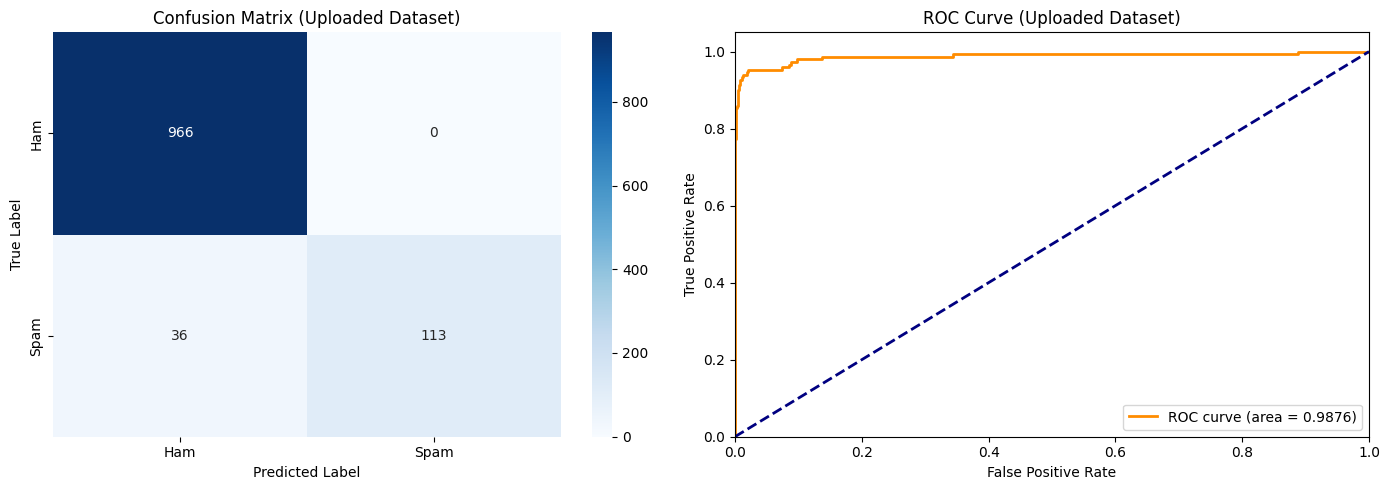

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

# 1. Re-initialize and train the Pipeline with the newly uploaded and processed data
model_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', lowercase=True)),
    ('classifier', LogisticRegression(random_state=42))
])

# 2. Perform 5-Fold Cross-Validation on your uploaded training set
cv_scores = cross_val_score(model_pipeline, X_train, y_train, cv=5, scoring='accuracy')
print(f"5-Fold Cross-Validation Accuracy Scores on Uploaded Data: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

# 3. Fit model on the full uploaded training set
model_pipeline.fit(X_train, y_train)

# 4. Predict on the uploaded test set
y_pred = model_pipeline.predict(X_test)
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

# 5. Output metrics
accuracy = accuracy_score(y_test, y_pred)
print(f"\nTest Set Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))

# 6. Generate and render the performance visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[0].set_title('Confusion Matrix (Uploaded Dataset)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve (Uploaded Dataset)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()